# Problema 1 — Inciso (e): ¿qué pasa si el modelo usa `SEX`?

Esta libreta responde al contraste del inciso (e): reentrenar el mismo
boosting **con `SEX` como variable de entrada** y comparar contra el modelo
principal, que la deja fuera. No cambia la decisión registrada: el modelo
principal sigue sin `SEX`; esta variante es un diagnóstico.

Reglas que respeta:

- **Mismo split 70/30** guardado en `resultados/split_indices.csv`.
- **Mismos hiperparámetros** que eligió `03_modelos` para el mejor modelo.
- **Misma calibración global isotónica** que eligió `04_calibracion`
  (`CalibratedClassifierCV(cv=5)` dentro del 70%), ajustada solo con el 70%.
- **Mismo umbral `1/6`** para todos.
- **Misma tabla y mismo bootstrap** de `05_tabla_grupos`, para que la
  comparación sea directa.
- Además, se mide qué variables se asocian con `SEX` y qué tan bien se puede
  predecir `SEX` desde las demás variables. Eso explica por qué quitar `SEX`
  del modelo no equivale a “cegarlo” al grupo.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency, pearsonr
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo.

    La raíz se reconoce porque contiene `common.py` y la carpeta `problema-1/`.
    Así la libreta funciona igual si se abre desde la raíz o desde
    `problema-1/`, y también cuando la ejecuta `nbconvert`.
    """
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-1").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-1" if (_RAIZ / "problema-1").is_dir() else _RAIZ

# Permite importar common.py (raíz) y los módulos de problema-1/.
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import G, L, SEED, UMBRAL  # noqa: E402
from data import TARGET, cargar_dataframe  # noqa: E402
import equidad as eq  # noqa: E402
import evidencia_datos as ev  # noqa: E402
import modelos as mo  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", None)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

N_BOOTSTRAP = 2000

print(f"SEED = {SEED}")
print(f"G = {G}, L = {L}, UMBRAL = G/(G+L) = {UMBRAL:.12f}")
print(f"Réplicas bootstrap = {N_BOOTSTRAP}")
print(f"Directorio de resultados = {RESULTADOS}")

SEED = 223210350
G = 1, L = 5, UMBRAL = G/(G+L) = 0.166666666667
Réplicas bootstrap = 2000
Directorio de resultados = /home/tito/repos/RDP/Examen_1_RDP/resultados


## 1. Carga y modelo con `SEX`

Se reconstruye el `Pipeline` del mejor modelo con `incluir_sexo=True`. Eso
agrega `SEX` a las columnas categóricas del preprocesamiento, junto con
`EDUCATION` y `MARRIAGE`. El resto de la configuración es idéntica al modelo
principal: mismos hiperparámetros, mismo split y misma calibración isotónica
global.

In [2]:
ruta_split = RESULTADOS / "split_indices.csv"
ruta_resumen = RESULTADOS / "03_resumen_modelos.csv"
ruta_metodo = RESULTADOS / "04_metodo_calibracion.csv"

for ruta in (ruta_split, ruta_resumen, ruta_metodo):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero las libretas 02, 03 y 04."
        )

df = cargar_dataframe()
columnas_pay = mo.obtener_columnas_pay(df)
idx_train, idx_test = ev.cargar_indices(ruta_split, df, TARGET)

idx_train_esperado, idx_test_esperado = ev.dividir_estratificado(
    df, TARGET, test_size=0.30, seed=SEED
)
if not (
    np.array_equal(idx_train, idx_train_esperado)
    and np.array_equal(idx_test, idx_test_esperado)
):
    raise ValueError(
        "El split guardado no coincide con el split reproducible de SEED. "
        "Revisa resultados/split_indices.csv antes de continuar."
    )

resumen = pd.read_csv(ruta_resumen)
mejor = resumen.loc[resumen["mejor_por_auc_cv"] == "sí"].iloc[0]
tabla_metodo = pd.read_csv(ruta_metodo)
metodo_calibracion = str(tabla_metodo.loc[0, "metodo_calibracion"])
if metodo_calibracion not in {"sin_calibrar", "sigmoid", "isotonic"}:
    raise ValueError(
        f"Método de calibración desconocido: '{metodo_calibracion}'."
    )

columnas_x_sexo = mo.columnas_entrada(df, TARGET, incluir_sexo=True)
if "SEX" not in columnas_x_sexo:
    raise ValueError("La variante con SEX debe incluir 'SEX' como entrada.")

X_train = df.iloc[idx_train][columnas_x_sexo].reset_index(drop=True)
y_train = df.iloc[idx_train][TARGET].reset_index(drop=True)
X_test = df.iloc[idx_test][columnas_x_sexo].reset_index(drop=True)
y_test = df.iloc[idx_test][TARGET].reset_index(drop=True).to_numpy(dtype=int)
sexo_train = df.iloc[idx_train]["SEX"].to_numpy(dtype=int)
sexo_test = df.iloc[idx_test]["SEX"].to_numpy(dtype=int)

pipeline_sexo = mo.construir_pipeline_desde_mejor(
    mejor, columnas_pay, seed=SEED, incluir_sexo=True
)
if metodo_calibracion == "sin_calibrar":
    modelo_sexo = pipeline_sexo
else:
    modelo_sexo = CalibratedClassifierCV(
        estimator=pipeline_sexo,
        method=metodo_calibracion,
        cv=5,
        n_jobs=1,
        ensemble=True,
    )

modelo_sexo.fit(X_train, y_train)
prob_test_sexo = modelo_sexo.predict_proba(X_test)[:, 1]

print(f"Mejor modelo base: {mejor['modelo']} ({mejor['modelo_id']}).")
print(f"Calibración: {metodo_calibracion}.")
print(f"Columnas de entrada ({len(columnas_x_sexo)}): {columnas_x_sexo}")
print(f"¿SEX está en las columnas de entrada? {'SEX' in columnas_x_sexo}")
print(
    "Modelo con SEX en prueba: AUC = "
    f"{roc_auc_score(y_test, prob_test_sexo):.6f}, log-loss = "
    f"{log_loss(y_test, prob_test_sexo):.6f}, media = "
    f"{prob_test_sexo.mean():.6f}, tasa real = {y_test.mean():.6f}."
)

Mejor modelo base: HistGradientBoostingClassifier (hist_gb).
Calibración: isotonic.
Columnas de entrada (23): ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
¿SEX está en las columnas de entrada? True
Modelo con SEX en prueba: AUC = 0.779162, log-loss = 0.430669, media = 0.221961, tasa real = 0.221222.


El modelo con `SEX` queda bien calibrado en promedio: su probabilidad media
(`0.221961`) es casi la tasa real de prueba (`0.221222`). Su AUC es
`0.779162`, prácticamente igual al del modelo sin `SEX` (`0.779463`), incluso
un poco menor. Es decir, agregar `SEX` no mejora la capacidad de ordenar
riesgos; lo que cambia es cómo se reparten los errores al aplicar el umbral.

## 2. Tabla por grupo con `SEX` como entrada

Se repite exactamente la tabla de `05_tabla_grupos`: `n`, `p_g`, tasa de
rechazo, `PPV`, `FPR`, `FNR`, celdas de la matriz de confusión y ganancia,
con el umbral único `1/6`.

In [3]:
tabla_sexo, avisos_sexo = eq.tabla_grupos(
    y_test, prob_test_sexo, sexo_test, umbral=UMBRAL
)
columnas_tabla = [
    "grupo",
    "n",
    "p_g",
    "tasa_rechazo",
    "PPV",
    "FPR",
    "FNR",
    "TP",
    "FN",
    "FP",
    "TN",
    "ganancia",
    "ganancia_por_solicitante",
]
display(tabla_sexo[columnas_tabla].round(6))
tabla_sexo[columnas_tabla].to_csv(
    RESULTADOS / "07_tabla_grupos.csv", index=False, float_format="%.8f"
)

if avisos_sexo:
    print("AVISOS de división entre cero:")
    for aviso in avisos_sexo:
        print(f"  - {aviso}")
else:
    print("Sin divisiones entre cero en la tabla del modelo con SEX.")

,grupo,n,p_g,tasa_rechazo,PPV,FPR,FNR,TP,FN,FP,TN,ganancia,ganancia_por_solicitante
0,Hombres (SEX=1),3584,0.232980,0.464007,0.380637,0.374682,0.241916,633,202,1030,1719,709.0,0.197824
1,Mujeres (SEX=2),5416,0.213442,0.380355,0.395631,0.292254,0.294983,815,341,1245,3015,1310.0,0.241876
2,Todos,9000,0.221222,0.413667,0.388934,0.324583,0.272727,1448,543,2275,4734,2019.0,0.224333


Sin divisiones entre cero en la tabla del modelo con SEX.


Con `SEX` como entrada, los hombres tienen una tasa de rechazo de `0.464007`
y las mujeres de `0.380355`; la brecha de tasa de rechazo es de `0.083652`.
La `PPV` es `0.380637` en hombres y `0.395631` en mujeres. El `FPR` de
hombres es `0.374682` y el de mujeres `0.292254`: la diferencia sube a
`0.082428`, casi el doble que en el modelo sin `SEX` (`0.042289`). El `FNR`
de hombres es `0.241916` y el de mujeres `0.294983`: la diferencia es
`-0.053067`, también más grande en valor absoluto que la del modelo sin
`SEX` (`-0.023922`). La ganancia total es `2019` unidades de `G`, superior a
`1984`, pero repartida de forma más desigual.

## 3. Bootstrap de las diferencias con `SEX`

Se repite el bootstrap de `05_tabla_grupos`: 2,000 réplicas de todo el
conjunto de prueba con reemplazo y la semilla `SEED`. Se calculan los
intervalos del 95% por percentiles para `FPR_H − FPR_M` y `FNR_H − FNR_M`.

In [4]:
rechazo_sexo = prob_test_sexo >= UMBRAL
replicas_sexo, replicas_invalidas_sexo = eq.bootstrap_diferencias(
    y_test,
    rechazo_sexo,
    sexo_test,
    metricas=("FPR", "FNR"),
    n_boot=N_BOOTSTRAP,
    seed=SEED,
)

filas_bootstrap_sexo = []
for metrica in ("FPR", "FNR"):
    observada = eq.diferencia_observada(tabla_sexo, metrica)
    filas_bootstrap_sexo.append(
        eq.resumen_bootstrap(
            f"{metrica}_H - {metrica}_M (con SEX)",
            observada,
            replicas_sexo[metrica],
            N_BOOTSTRAP,
        )
    )
tabla_bootstrap_sexo = pd.DataFrame(filas_bootstrap_sexo)
display(tabla_bootstrap_sexo.round(6))
tabla_bootstrap_sexo.to_csv(
    RESULTADOS / "07_bootstrap_ic95.csv", index=False, float_format="%.8f"
)

pd.DataFrame(
    {
        "replica": np.arange(1, N_BOOTSTRAP + 1),
        "dif_FPR_H_menos_FPR_M": replicas_sexo["FPR"],
        "dif_FNR_H_menos_FNR_M": replicas_sexo["FNR"],
    }
).to_csv(
    RESULTADOS / "07_bootstrap_replicas.csv",
    index=False,
    float_format="%.8f",
)

print(
    f"Réplicas bootstrap inválidas: {replicas_invalidas_sexo} "
    f"de {N_BOOTSTRAP}."
)

,diferencia,observada,media_bootstrap,sd_bootstrap,ic95_inferior,ic95_superior,contiene_cero,replicas_validas,replicas_invalidas
0,FPR_H - FPR_M (con SEX),0.082428,0.082507,0.011341,0.060641,0.104318,no,2000,0
1,FNR_H - FNR_M (con SEX),-0.053067,-0.053082,0.020479,-0.094352,-0.014404,no,2000,0


Réplicas bootstrap inválidas: 0 de 2000.


Los dos intervalos **excluyen el cero**. Para `FPR_H − FPR_M`, la diferencia
observada es `0.082428` con IC `[0.060641, 0.104318]`; para
`FNR_H − FNR_M`, es `-0.053067` con IC `[-0.094352, -0.014404]`. En el
modelo sin `SEX`, la diferencia de `FPR` también era significativa
(`0.042289`, IC `[0.020183, 0.064465]`), pero la de `FNR` no
(`-0.023922`, IC `[-0.064162, 0.015438]`). Con `SEX` como entrada, la
disparidad de `FPR` se duplica y la de `FNR` pasa a ser significativa: el
atributo protegido no elimina las diferencias, las reorganiza y las agrava.

## 4. Comparación directa contra el modelo sin `SEX`

La tabla siguiente junta los dos modelos. Las columnas `delta_*` son
`con SEX − sin SEX`, de modo que un valor positivo indica que el modelo con
`SEX` aumenta esa cantidad.

In [5]:
ruta_tabla_05 = RESULTADOS / "05_tabla_grupos.csv"
ruta_bootstrap_05 = RESULTADOS / "05_bootstrap_ic95.csv"
ruta_metricas_04 = RESULTADOS / "04_metricas_test.csv"
ruta_probabilidades_04 = RESULTADOS / "04_probabilidades_calibradas_test.csv"
for ruta in (
    ruta_tabla_05,
    ruta_bootstrap_05,
    ruta_metricas_04,
    ruta_probabilidades_04,
):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero las libretas 04 y 05."
        )

tabla_05 = pd.read_csv(ruta_tabla_05)
bootstrap_05 = pd.read_csv(ruta_bootstrap_05)
metricas_04 = pd.read_csv(ruta_metricas_04)
tabla_probabilidades_04 = pd.read_csv(ruta_probabilidades_04)
fila_isotonic = metricas_04.loc[
    metricas_04["metodo_id"] == "isotonic"
].iloc[0]
auc_sin_sexo = float(fila_isotonic["auc"])
auc_con_sexo = float(roc_auc_score(y_test, prob_test_sexo))

# Reconstruimos la tabla total sin SEX con las probabilidades calibradas de 04.
# 05_tabla_grupos.csv solo guarda hombres y mujeres; el total se recalcula para
# no confundir la fila de mujeres con el agregado.
if not np.array_equal(
    tabla_probabilidades_04["indice"].to_numpy(), idx_test
):
    raise ValueError(
        "Los índices de 04_probabilidades_calibradas_test.csv no coinciden "
        "con el split."
    )
prob_test_sin_sexo = tabla_probabilidades_04[
    "prob_calibrada"
].to_numpy(dtype=float)
tabla_sin_sexo, _ = eq.tabla_grupos(
    y_test, prob_test_sin_sexo, sexo_test, umbral=UMBRAL
)

h_05 = tabla_sin_sexo.loc[
    tabla_sin_sexo["grupo"] == eq.GRUPO_HOMBRES
].iloc[0]
m_05 = tabla_sin_sexo.loc[
    tabla_sin_sexo["grupo"] == eq.GRUPO_MUJERES
].iloc[0]
total_05 = tabla_sin_sexo.loc[
    tabla_sin_sexo["grupo"] == eq.GRUPO_TODOS
].iloc[0]

h_07 = tabla_sexo.loc[tabla_sexo["grupo"] == eq.GRUPO_HOMBRES].iloc[0]
m_07 = tabla_sexo.loc[tabla_sexo["grupo"] == eq.GRUPO_MUJERES].iloc[0]
total_07 = tabla_sexo.loc[tabla_sexo["grupo"] == eq.GRUPO_TODOS].iloc[0]

comparacion = pd.DataFrame(
    [
        {
            "modelo": "Sin SEX (principal)",
            "auc_test": auc_sin_sexo,
            "ganancia_test": float(total_05["ganancia"]),
            "ganancia_por_solicitante": float(
                total_05["ganancia_por_solicitante"]
            ),
            "tasa_rechazo": float(total_05["tasa_rechazo"]),
            "PPV": float(total_05["PPV"]),
            "FPR_H": float(h_05["FPR"]),
            "FPR_M": float(m_05["FPR"]),
            "dif_FPR": float(h_05["FPR"] - m_05["FPR"]),
            "FNR_H": float(h_05["FNR"]),
            "FNR_M": float(m_05["FNR"]),
            "dif_FNR": float(h_05["FNR"] - m_05["FNR"]),
            "ic95_FPR": (
                f"[{bootstrap_05.loc[0, 'ic95_inferior']:.6f}, "
                f"{bootstrap_05.loc[0, 'ic95_superior']:.6f}]"
            ),
            "ic95_FNR": (
                f"[{bootstrap_05.loc[1, 'ic95_inferior']:.6f}, "
                f"{bootstrap_05.loc[1, 'ic95_superior']:.6f}]"
            ),
        },
        {
            "modelo": "Con SEX (contraste)",
            "auc_test": auc_con_sexo,
            "ganancia_test": float(total_07["ganancia"]),
            "ganancia_por_solicitante": float(
                total_07["ganancia_por_solicitante"]
            ),
            "tasa_rechazo": float(total_07["tasa_rechazo"]),
            "PPV": float(total_07["PPV"]),
            "FPR_H": float(h_07["FPR"]),
            "FPR_M": float(m_07["FPR"]),
            "dif_FPR": float(h_07["FPR"] - m_07["FPR"]),
            "FNR_H": float(h_07["FNR"]),
            "FNR_M": float(m_07["FNR"]),
            "dif_FNR": float(h_07["FNR"] - m_07["FNR"]),
            "ic95_FPR": (
                f"[{tabla_bootstrap_sexo.loc[0, 'ic95_inferior']:.6f}, "
                f"{tabla_bootstrap_sexo.loc[0, 'ic95_superior']:.6f}]"
            ),
            "ic95_FNR": (
                f"[{tabla_bootstrap_sexo.loc[1, 'ic95_inferior']:.6f}, "
                f"{tabla_bootstrap_sexo.loc[1, 'ic95_superior']:.6f}]"
            ),
        },
    ]
)
comparacion["delta_auc"] = comparacion["auc_test"] - auc_sin_sexo
comparacion["delta_ganancia"] = (
    comparacion["ganancia_test"] - float(total_05["ganancia"])
)
comparacion["delta_dif_FPR"] = (
    comparacion["dif_FPR"] - float(h_05["FPR"] - m_05["FPR"])
)
comparacion["delta_dif_FNR"] = (
    comparacion["dif_FNR"] - float(h_05["FNR"] - m_05["FNR"])
)
display(comparacion.round(6))
comparacion.to_csv(
    RESULTADOS / "07_comparacion_modelos.csv",
    index=False,
    float_format="%.8f",
)

print(
    "Ganancia adicional del modelo con SEX: "
    f"{comparacion.loc[1, 'delta_ganancia']:.0f} unidades de G "
    f"({100.0 * comparacion.loc[1, 'delta_ganancia'] / float(total_05['ganancia']):.4f}% "
    "sobre la ganancia sin SEX)."
)
print(
    "Cambio de la brecha de FPR al incluir SEX: "
    f"{comparacion.loc[1, 'delta_dif_FPR']:+.6f}."
)
print(
    "Cambio de la brecha de FNR al incluir SEX: "
    f"{comparacion.loc[1, 'delta_dif_FNR']:+.6f}."
)

,modelo,auc_test,ganancia_test,ganancia_por_solicitante,tasa_rechazo,PPV,FPR_H,FPR_M,dif_FPR,FNR_H,FNR_M,dif_FNR,ic95_FPR,ic95_FNR,delta_auc,delta_ganancia,delta_dif_FPR,delta_dif_FNR
0,Sin SEX (principal),0.779463,1984.0,0.220444,0.428889,0.379534,0.367406,0.325117,0.042289,0.250299,0.274221,-0.023922,"[0.020183, 0.064465]","[-0.064162, 0.015438]",0.000000,0.0,0.000000,0.000000
1,Con SEX (contraste),0.779162,2019.0,0.224333,0.413667,0.388934,0.374682,0.292254,0.082428,0.241916,0.294983,-0.053067,"[0.060641, 0.104318]","[-0.094352, -0.014404]",-0.000302,35.0,0.040139,-0.029144


Ganancia adicional del modelo con SEX: 35 unidades de G (1.7641% sobre la ganancia sin SEX).
Cambio de la brecha de FPR al incluir SEX: +0.040139.
Cambio de la brecha de FNR al incluir SEX: -0.029144.


El modelo con `SEX` gana `35` unidades de `G` (`1.7641%`) y su AUC es
`0.000302` menor. Esa combinación es posible porque la ganancia depende del
umbral y de la distribución de errores, no solo del orden global. El precio
es una brecha de `FPR` que pasa de `0.042289` a `0.082428` (`+0.040139`) y
una brecha de `FNR` que pasa de `-0.023922` a `-0.053067` (`-0.029144`).
Incluir el atributo protegido no es una solución de equidad: mejora la
ganancia promedio y empeora la disparidad entre grupos.

## 5. ¿Qué variables se asocian con `SEX`?

Si `SEX` se excluye del modelo, otras variables pueden actuar como
sustitutas. Para medirlo se calculan dos estadísticos sobre el 70% de
entrenamiento:

- **V de Cramér** para variables categóricas (`EDUCATION`, `MARRIAGE`,
  `PAY_0..PAY_6`). Va de `0` (independencia) a `1` (asociación perfecta).
- **Correlación punto-biserial** para variables numéricas: es la correlación
  de Pearson entre la variable y el indicador `SEX=1` (hombre). Su signo
  indica dirección y su valor absoluto, intensidad.

La tabla se ordena por valor absoluto del estadístico.

In [6]:
columnas_categoricas = ["EDUCATION", "MARRIAGE", *columnas_pay]
columnas_numericas = [
    "LIMIT_BAL",
    "AGE",
    *[f"BILL_AMT{i}" for i in range(1, 7)],
    *[f"PAY_AMT{i}" for i in range(1, 7)],
]
df_train = df.iloc[idx_train]

filas_asociacion = []
for columna in columnas_categoricas:
    tabla_contingencia = pd.crosstab(df_train[columna], df_train["SEX"])
    chi2, p_valor, _, _ = chi2_contingency(tabla_contingencia)
    n = int(tabla_contingencia.to_numpy().sum())
    grados = min(tabla_contingencia.shape) - 1
    v_cramer = (
        float(np.sqrt(chi2 / (n * grados))) if grados > 0 and n > 0 else np.nan
    )
    filas_asociacion.append(
        {
            "variable": columna,
            "tipo": "categórica",
            "estadistico": "V de Cramér",
            "valor": v_cramer,
            "abs_valor": abs(v_cramer) if np.isfinite(v_cramer) else np.nan,
            "p_valor": float(p_valor),
            "direccion": "—",
            "n": n,
            "categorias": int(df_train[columna].nunique()),
        }
    )

for columna in columnas_numericas:
    x = df_train[columna].to_numpy(dtype=float)
    indicador_hombre = (df_train["SEX"].to_numpy() == 1).astype(float)
    r, p_valor = pearsonr(x, indicador_hombre)
    filas_asociacion.append(
        {
            "variable": columna,
            "tipo": "numérica",
            "estadistico": "correlación punto-biserial",
            "valor": float(r),
            "abs_valor": abs(float(r)),
            "p_valor": float(p_valor),
            "direccion": (
                "hombres mayor" if r > 0 else "mujeres mayor" if r < 0 else "—"
            ),
            "n": int(len(x)),
            "categorias": int(df_train[columna].nunique()),
        }
    )

asociaciones = pd.DataFrame(filas_asociacion).sort_values(
    "abs_valor", ascending=False
).reset_index(drop=True)
display(asociaciones.round(6))
asociaciones.to_csv(
    RESULTADOS / "07_asociaciones_sexo.csv",
    index=False,
    float_format="%.8f",
)

print("Variables más asociadas con SEX (valor absoluto):")
for _, fila in asociaciones.head(10).iterrows():
    print(
        f"  - {fila['variable']}: {fila['estadistico']} = "
        f"{fila['valor']:.6f} (p = {fila['p_valor']:.3g})."
    )

,variable,tipo,estadistico,valor,abs_valor,p_valor,direccion,n,categorias
0,AGE,numérica,correlación punto-biserial,0.089910,0.089910,0.000000,hombres mayor,21000,55
1,PAY_2,categórica,V de Cramér,0.082674,0.082674,0.000000,—,21000,11
2,PAY_3,categórica,V de Cramér,0.079117,0.079117,0.000000,—,21000,11
3,PAY_4,categórica,V de Cramér,0.068502,0.068502,0.000000,—,21000,11
4,PAY_0,categórica,V de Cramér,0.067767,0.067767,0.000000,—,21000,11
5,PAY_5,categórica,V de Cramér,0.062513,0.062513,0.000000,—,21000,10
6,PAY_6,categórica,V de Cramér,0.053538,0.053538,0.000000,—,21000,10
7,MARRIAGE,categórica,V de Cramér,0.039343,0.039343,0.000000,—,21000,4
8,BILL_AMT1,numérica,correlación punto-biserial,0.032371,0.032371,0.000003,hombres mayor,21000,16659
9,EDUCATION,categórica,V de Cramér,0.030965,0.030965,0.002620,—,21000,7


Variables más asociadas con SEX (valor absoluto):
  - AGE: correlación punto-biserial = 0.089910 (p = 5.96e-39).
  - PAY_2: V de Cramér = 0.082674 (p = 7.94e-26).
  - PAY_3: V de Cramér = 0.079117 (p = 2.36e-23).
  - PAY_4: V de Cramér = 0.068502 (p = 1.07e-16).
  - PAY_0: V de Cramér = 0.067767 (p = 2.8e-16).
  - PAY_5: V de Cramér = 0.062513 (p = 6.28e-14).
  - PAY_6: V de Cramér = 0.053538 (p = 1.23e-09).
  - MARRIAGE: V de Cramér = 0.039343 (p = 4.1e-07).
  - BILL_AMT1: correlación punto-biserial = 0.032371 (p = 2.71e-06).
  - EDUCATION: V de Cramér = 0.030965 (p = 0.00262).


Las asociaciones más fuertes son moderadas, no triviales: `AGE`
(`0.089910`), `PAY_2` (`0.082674`), `PAY_3` (`0.079117`), `PAY_4`
(`0.068502`), `PAY_0` (`0.067767`), `PAY_5` (`0.062513`) y `PAY_6`
(`0.053538`). Ninguna variable por sí sola identifica el sexo, pero varias
cargan información sobre el grupo. Esa es la primera señal de que excluir
`SEX` no vuelve al modelo ciego al sexo: el modelo puede reconstruir parte
de esa información con las demás variables.

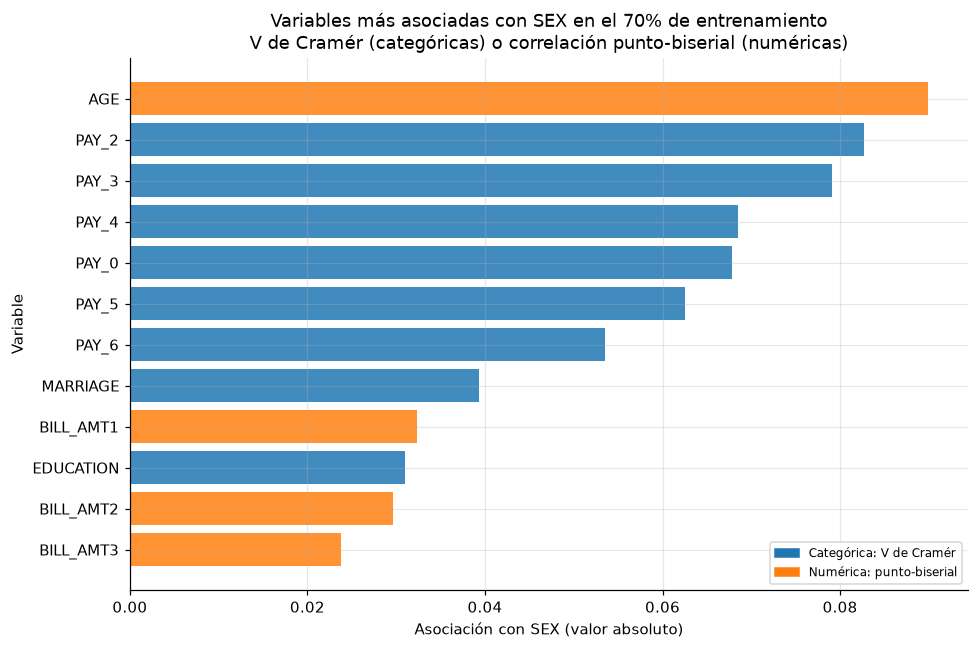

Figura guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/07_asociaciones_sexo.png


In [7]:
top_asociaciones = asociaciones.head(12).iloc[::-1]
colores = [
    "tab:blue" if tipo == "categórica" else "tab:orange"
    for tipo in top_asociaciones["tipo"]
]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_asociaciones["variable"],
    top_asociaciones["abs_valor"],
    color=colores,
    alpha=0.85,
)
ax.set_xlabel("Asociación con SEX (valor absoluto)")
ax.set_ylabel("Variable")
ax.set_title(
    "Variables más asociadas con SEX en el 70% de entrenamiento\n"
    "V de Cramér (categóricas) o correlación punto-biserial (numéricas)"
)
from matplotlib.patches import Patch  # noqa: E402

ax.legend(
    handles=[
        Patch(color="tab:blue", label="Categórica: V de Cramér"),
        Patch(color="tab:orange", label="Numérica: punto-biserial"),
    ],
    loc="lower right",
    fontsize=8,
)
fig.tight_layout()
ruta_asociaciones = RESULTADOS / "07_asociaciones_sexo.png"
fig.savefig(ruta_asociaciones, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {ruta_asociaciones}")

La gráfica ordena las asociaciones y muestra que las variables de morosidad
(`PAY_*`) y la edad son las que más se relacionan con `SEX`. Son asociaciones
débiles en términos absolutos, pero suficientes para que un clasificador
encuentre señal. Esa señal es la que explica por qué el modelo sin `SEX`
sigue produciendo diferencias por grupo: no necesita el atributo para
aproximarse a él.

## 6. ¿Qué tan predecible es `SEX` con las demás variables?

Se entrena un clasificador auxiliar que intenta predecir `SEX` usando todas
las variables del modelo, **sin** `SEX`. Se reporta el AUC en validación
cruzada de 5 particiones sobre el 70% y en el 30% de prueba. Un AUC de `0.5`
sería indistinguible del azar; un AUC alto indicaría que el grupo es
reconstruible desde las demás variables.

In [8]:
columnas_sexo = [*columnas_categoricas, *columnas_numericas]
X_sexo_train = df.iloc[idx_train][columnas_sexo].reset_index(drop=True)
X_sexo_test = df.iloc[idx_test][columnas_sexo].reset_index(drop=True)
y_sexo_train = (df.iloc[idx_train]["SEX"].to_numpy() == 1).astype(int)
y_sexo_test = (df.iloc[idx_test]["SEX"].to_numpy() == 1).astype(int)

preprocesamiento_sexo = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            columnas_categoricas,
        ),
        ("numericas", StandardScaler(), columnas_numericas),
    ],
    remainder="drop",
)
clasificador_sexo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesamiento_sexo),
        (
            "modelo",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                random_state=SEED,
            ),
        ),
    ]
)

folds_sexo = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
auc_cv_sexo = cross_val_score(
    clasificador_sexo,
    X_sexo_train,
    y_sexo_train,
    cv=folds_sexo,
    scoring="roc_auc",
    n_jobs=1,
)
clasificador_sexo.fit(X_sexo_train, y_sexo_train)
prob_sexo_test = clasificador_sexo.predict_proba(X_sexo_test)[:, 1]
auc_test_sexo = float(roc_auc_score(y_sexo_test, prob_sexo_test))

tabla_clasificador = pd.DataFrame(
    [
        {
            "modelo": "HistGradientBoosting para predecir SEX",
            "auc_cv_medio": float(auc_cv_sexo.mean()),
            "auc_cv_std": float(auc_cv_sexo.std(ddof=1)),
            "auc_test": auc_test_sexo,
            "variables_de_entrada": len(columnas_sexo),
            "incluye_SEX": "no",
        }
    ]
)
display(tabla_clasificador.round(6))
tabla_clasificador.to_csv(
    RESULTADOS / "07_clasificador_sexo.csv",
    index=False,
    float_format="%.8f",
)

print(
    "AUC de validación cruzada para predecir SEX: "
    f"{auc_cv_sexo.mean():.6f} ± {auc_cv_sexo.std(ddof=1):.6f}."
)
print(f"AUC de prueba para predecir SEX: {auc_test_sexo:.6f}.")

,modelo,auc_cv_medio,auc_cv_std,auc_test,variables_de_entrada,incluye_SEX
0,HistGradientBoosting para predecir SEX,0.650929,0.004657,0.649996,22,no


AUC de validación cruzada para predecir SEX: 0.650929 ± 0.004657.
AUC de prueba para predecir SEX: 0.649996.


El clasificador alcanza un AUC de `0.650929 ± 0.004657` en validación
cruzada y `0.649996` en prueba, muy por encima de `0.5`. No es un
identificador perfecto, pero demuestra que las demás variables contienen
información sobre el sexo. Por eso el modelo principal, aunque no reciba
`SEX`, puede aproximar el grupo y producir patrones distintos por grupo. La
transparencia exige auditar por `SEX` precisamente porque el atributo no
desaparece del problema al quitarlo de la lista de entradas.

## 7. Por qué no desaparecen las diferencias: tasas base distintas

La razón de fondo es la del inciso (b) de la teoría. Para cada grupo `g`,
la identidad

$$
FPR_g = \frac{p_g}{1-p_g} \cdot \frac{1-PPV_g}{PPV_g} \cdot (1-FNR_g)
$$

relaciona las métricas con la tasa base `p_g`. En prueba, los hombres tienen
`p_H = 0.232980` y las mujeres `p_M = 0.213442`: las tasas base **no son
iguales**. Si se igualan `PPV` y `FNR` en ambos grupos, la identidad obliga a
que

$$
FPR_H = FPR_M \quad \Longleftrightarrow \quad
\frac{p_H}{1-p_H} = \frac{p_M}{1-p_M}
\quad \Longleftrightarrow \quad p_H = p_M,
$$

salvo el caso degenerado en que `PPV = 1` (no hay falsos positivos) o
`FNR = 1` (nunca se rechaza, y la `PPV` queda indefinida). Como `p_H ≠ p_M`,
no se pueden igualar a la vez `PPV`, `FNR` y `FPR` con un clasificador no
degenerado. Hay que elegir qué disparidad se corrige y cuánta ganancia se
sacrifica.

El modelo con `SEX` no escapa de esa restricción: al recibir el grupo, puede
ajustar mejor la probabilidad promedio, pero sigue operando sobre dos
poblaciones con tasas base distintas. Por eso la brecha de `FPR` no
desaparece; de hecho, aumenta. La solución de equidad no es meter el
atributo, sino decidir explícitamente qué métrica se va a igualar y aplicar
una política de umbrales o de intervención, como en `06_intervencion`.

## 8. Cierre del inciso (e)

- El modelo con `SEX` usa el mismo split, los mismos hiperparámetros, la
  misma calibración isotónica global y el mismo umbral `1/6`.
- Su AUC de prueba es `0.779162`, ligeramente menor que el del modelo sin
  `SEX` (`0.779463`), pero su ganancia sube de `1984` a `2019` unidades de
  `G` (`+35`, `+1.7641%`).
- Las diferencias entre grupos **no desaparecen**: la brecha de `FPR` pasa de
  `0.042289` a `0.082428` y su IC 95% `[0.060641, 0.104318]` no contiene el
  cero; la brecha de `FNR` pasa de `-0.023922` a `-0.053067` y su IC 95%
  `[-0.094352, -0.014404]` tampoco contiene el cero.
- Las variables del modelo se asocian con `SEX` de forma moderada; las más
  asociadas son `AGE` (`0.089910`) y varias `PAY_*` (alrededor de
  `0.05`–`0.08`). Un clasificador auxiliar predice `SEX` con AUC `0.650929`
  en CV y `0.649996` en prueba, así que quitar `SEX` no elimina la
  información del grupo.
- La explicación de fondo es la imposibilidad de igualar todas las métricas
  cuando `p_H ≠ p_M`. La decisión registrada de dejar `SEX` fuera del modelo
  principal se mantiene; la equidad se atiende con auditoría y con la
  intervención de umbrales de `06_intervencion`, no con el atributo como
  entrada.